# Day 5 – Feature Encoding
## Holistic Data Preparer | Fintech: Customer Credit Risk Prediction


## 1. Project folders and imports

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, LabelEncoder

RANDOM_STATE = 42
EXPECTED_COLUMNS = [
    "customer_id", "age", "gender", "region", "education_level",
    "employment_type", "annual_income", "loan_amount", "loan_purpose",
    "credit_score", "repayment_history", "transaction_count",
    "spending_ratio", "join_date", "default_flag"
]
PROJECT_ROOT = next((p for p in [Path.cwd(), Path.cwd().parent] if (p / "data").exists()), Path.cwd())
RAW_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
REPORT_DIR = PROJECT_ROOT / "reports"
for folder in [RAW_DIR, PROCESSED_DIR, REPORT_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

## 2. Load and validate the Day 4 dataset

In [2]:
candidate_paths = [
    PROCESSED_DIR / "customer_credit_risk_day04_outlier_treated.csv",
    PROJECT_ROOT / "data" / "interim" / "customer_credit_risk_day03_imputed.csv",
    RAW_DIR / "customer_credit_risk_synthetic_raw.csv"
]
input_path = next((p for p in candidate_paths if p.exists()), None)
if input_path is None:
    raise FileNotFoundError("No project dataset found. Place the synthetic dataset in data/raw/.")
df = pd.read_csv(input_path)
assert df.columns.tolist() == EXPECTED_COLUMNS, "Input schema does not match the project schema."
assert df["customer_id"].is_unique, "customer_id must be unique."
assert set(df["default_flag"].dropna().unique()).issubset({0, 1}), "Target must contain only 0 and 1."
print("Input file:", input_path)
print("Dataset shape:", df.shape)
display(df.head())

Input file: c:\Users\tejpa\OneDrive\Documents\R & W Projects\Data Preparing & Processing\Holistic-data-preparer\data\processed\customer_credit_risk_day04_outlier_treated.csv
Dataset shape: (1000, 15)


,customer_id,age,gender,region,education_level,employment_type,annual_income,loan_amount,loan_purpose,credit_score,repayment_history,transaction_count,spending_ratio,join_date,default_flag
0,100001,25.0,Other,West,Postgraduate,Self-employed,567257.078077,203652.899789,Personal,695.653979,Good,35.0,0.245852,2021-01-01,0
1,100002,55.0,Other,North,Postgraduate,Unemployed,549222.003633,357645.215003,Vehicle,621.651638,Average,34.0,0.487278,2021-01-02,0
2,100003,50.0,Male,South,Postgraduate,Salaried,819172.491746,190787.099515,Education,819.857156,Good,29.0,0.272024,2021-01-03,0
3,100004,40.0,Other,South,Postgraduate,Self-employed,830202.917161,245846.946211,Home,730.222607,Average,40.0,0.411828,2021-01-04,1
4,100005,40.0,Female,West,Postgraduate,Self-employed,532280.826257,76055.814034,Personal,661.062092,Good,31.0,0.188984,2021-01-05,0


## 3. Identify categorical feature

In [3]:
categorical_features = [
    "gender", "region", "education_level", "employment_type",
    "loan_purpose", "repayment_history"
]
nominal_features = [
    "gender", "region", "education_level", "employment_type", "loan_purpose"
]
ordinal_feature = ["repayment_history"]

category_summary = pd.DataFrame({
    "feature": categorical_features,
    "unique_category_count": [df[c].nunique(dropna=True) for c in categorical_features],
    "missing_count": [df[c].isna().sum() for c in categorical_features],
    "sample_categories": [", ".join(map(str, df[c].dropna().unique()[:6])) for c in categorical_features]
})
display(category_summary)

,feature,unique_category_count,missing_count,sample_categories
0,gender,3,0,"Other, Male, Female"
1,region,4,0,"West, North, South, East"
2,education_level,3,0,"Postgraduate, Graduate, High School"
3,employment_type,4,0,"Self-employed, Unemployed, Salaried, Business"
4,loan_purpose,5,0,"Personal, Vehicle, Education, Home, Business"
5,repayment_history,3,0,"Good, Average, Poor"


## 4. Prepare data and split before fitting encoders

In [4]:
df["join_date"] = pd.to_datetime(df["join_date"], errors="coerce")
numeric_features = ["age", "annual_income", "loan_amount", "credit_score", "transaction_count", "spending_ratio"]

train_idx, test_idx = train_test_split(
    df.index, test_size=0.20, random_state=RANDOM_STATE, stratify=df["default_flag"]
)
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()

# Learn numeric and categorical fill values from training data only.
numeric_fill = train[numeric_features].median()
categorical_fill = {c: train[c].mode(dropna=True).iloc[0] for c in categorical_features}

for frame in (train, test):
    for c in numeric_features:
        frame[c] = pd.to_numeric(frame[c], errors="coerce").fillna(numeric_fill[c])
    for c in categorical_features:
        frame[c] = frame[c].fillna(categorical_fill[c])
    frame["join_year"] = frame["join_date"].dt.year
    frame["join_month"] = frame["join_date"].dt.month

print("Training rows:", len(train), "| Testing rows:", len(test))

Training rows: 800 | Testing rows: 200


## 5. Label Encoding

In [5]:
label_encoder = LabelEncoder()
label_encoder.fit(train["gender"])

label_mapping = {label: int(label_encoder.transform([label])[0]) for label in label_encoder.classes_}
label_demo = pd.DataFrame({
    "original_gender": train["gender"].head(12).to_numpy(),
    "encoded_gender": label_encoder.transform(train["gender"].head(12))
})
print("Learned mapping:", label_mapping)
display(label_demo)

Learned mapping: {'Female': 0, 'Male': 1, 'Other': 2}


,original_gender,encoded_gender
0,Other,2
1,Male,1
2,Female,0
3,Male,1
4,Female,0
5,Female,0
6,Female,0
7,Female,0
8,Female,0
9,Other,2


## 6. One-Hot Encoding

In [6]:
try:
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
except TypeError:  # Compatibility with older scikit-learn versions
    one_hot_encoder = OneHotEncoder(handle_unknown="ignore", sparse=False)

one_hot_encoder.fit(train[nominal_features])
ohe_train_array = one_hot_encoder.transform(train[nominal_features])
ohe_test_array = one_hot_encoder.transform(test[nominal_features])

ohe_columns = one_hot_encoder.get_feature_names_out(nominal_features)
ohe_train = pd.DataFrame(ohe_train_array, columns=ohe_columns, index=train.index)
ohe_test = pd.DataFrame(ohe_test_array, columns=ohe_columns, index=test.index)

display(ohe_train.head())
print("Number of one-hot columns:", len(ohe_columns))

,gender_Female,gender_Male,gender_Other,region_East,region_North,region_South,region_West,education_level_Graduate,education_level_High School,education_level_Postgraduate,employment_type_Business,employment_type_Salaried,employment_type_Self-employed,employment_type_Unemployed,loan_purpose_Business,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_purpose_Vehicle
353,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
583,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
585,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
565,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
342,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


Number of one-hot columns: 19


## 7. Ordinal Encoding

In [7]:
repayment_order = ["Poor", "Fair", "Good", "Excellent"]
ordinal_encoder = OrdinalEncoder(
    categories=[repayment_order],
    handle_unknown="use_encoded_value",
    unknown_value=-1
)
ordinal_encoder.fit(train[ordinal_feature])

ordinal_train = pd.Series(
    ordinal_encoder.transform(train[ordinal_feature]).ravel(),
    index=train.index, name="repayment_history_ordinal"
)
ordinal_test = pd.Series(
    ordinal_encoder.transform(test[ordinal_feature]).ravel(),
    index=test.index, name="repayment_history_ordinal"
)

ordinal_mapping = pd.DataFrame({
    "category": repayment_order,
    "encoded_value": range(len(repayment_order))
})
display(ordinal_mapping)

,category,encoded_value
0,Poor,0
1,Fair,1
2,Good,2
3,Excellent,3


## 8. Frequency Encoding

In [8]:
frequency_maps = {
    c: train[c].value_counts(normalize=True)
    for c in categorical_features
}

frequency_train = pd.DataFrame(index=train.index)
frequency_test = pd.DataFrame(index=test.index)

for c in categorical_features:
    frequency_train[c + "_frequency"] = train[c].map(frequency_maps[c]).fillna(0)
    frequency_test[c + "_frequency"] = test[c].map(frequency_maps[c]).fillna(0)

display(frequency_train.head())

,gender_frequency,region_frequency,education_level_frequency,employment_type_frequency,loan_purpose_frequency,repayment_history_frequency
353,0.31125,0.29125,0.3325,0.3425,0.21250,0.6125
583,0.33250,0.23500,0.3275,0.2025,0.21250,0.6125
585,0.35625,0.23500,0.3275,0.2025,0.21875,0.2675
565,0.33250,0.29125,0.3275,0.3425,0.21750,0.2675
342,0.35625,0.23500,0.3275,0.3425,0.21750,0.6125


## 9. Compare encoding methods

| Method | Best suited for | Main advantage | Main limitation |
|---|---|---|---|
| Label | Compact category labels or specific algorithms | Few columns | Artificial order may be implied |
| One-Hot | Nominal categories | No ordinal relationship imposed | Can increase dimensionality |
| Ordinal | Genuinely ordered categories | Preserves rank | Incorrect order misleads model |
| Frequency | Some high-cardinality categories | Compact representation | Categories with equal frequency become indistinguishable |

In [9]:
method_comparison = pd.DataFrame([
    {"method":"Label Encoding","use_case":"Single categorical variable; mainly demonstration here","advantage":"Compact integer codes","limitation":"Can imply false order for nominal categories"},
    {"method":"One-Hot Encoding","use_case":"Nominal features","advantage":"Does not impose category order","limitation":"Can create many columns"},
    {"method":"Ordinal Encoding","use_case":"Repayment history with defined order","advantage":"Preserves known ranking","limitation":"Requires a defensible category order"},
    {"method":"Frequency Encoding","use_case":"Potentially high-cardinality features","advantage":"Compact numeric representation","limitation":"Different categories may share a frequency"}
])
display(method_comparison)
method_comparison.to_csv(REPORT_DIR / "day05_encoding_method_comparison.csv", index=False)

,method,use_case,advantage,limitation
0,Label Encoding,Single categorical variable; mainly demonstrat...,Compact integer codes,Can imply false order for nominal categories
1,One-Hot Encoding,Nominal features,Does not impose category order,Can create many columns
2,Ordinal Encoding,Repayment history with defined order,Preserves known ranking,Requires a defensible category order
3,Frequency Encoding,Potentially high-cardinality features,Compact numeric representation,Different categories may share a frequency


## 10. Build the final encoded train and test datasets

The final feature matrix uses:
- Numeric customer features (unchanged in this day).
- One-hot encoded nominal features.
- Ordinal encoded repayment history.
- Calendar features derived from `join_date`.

We do not include Label Encoding or Frequency Encoding in the final baseline matrix; they remain documented alternatives for comparison. The target is kept separately from the features during model development.

In [10]:
base_features = numeric_features + ["join_year", "join_month"]

X_train_encoded = pd.concat(
    [train[base_features], ohe_train, ordinal_train], axis=1
)
X_test_encoded = pd.concat(
    [test[base_features], ohe_test, ordinal_test], axis=1
)

y_train = train["default_flag"].copy()
y_test = test["default_flag"].copy()

assert X_train_encoded.columns.tolist() == X_test_encoded.columns.tolist()
assert "customer_id" not in X_train_encoded.columns
assert "default_flag" not in X_train_encoded.columns

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)
display(X_train_encoded.head())

Encoded training shape: (800, 28)
Encoded testing shape: (200, 28)


,age,annual_income,loan_amount,credit_score,transaction_count,spending_ratio,join_year,join_month,gender_Female,gender_Male,...,employment_type_Business,employment_type_Salaried,employment_type_Self-employed,employment_type_Unemployed,loan_purpose_Business,loan_purpose_Education,loan_purpose_Home,loan_purpose_Personal,loan_purpose_Vehicle,repayment_history_ordinal
353,40.0,508416.552511,244510.406980,758.119606,32.0,0.094949,2021.0,12.0,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0
583,23.0,710050.266070,271603.406551,643.503475,38.0,0.274127,2022.0,8.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,2.0
585,62.0,775809.020180,199219.357679,659.752852,19.0,0.180851,2022.0,8.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-1.0
565,31.0,572286.387798,278210.480194,716.431453,41.0,0.315587,2022.0,7.0,0.0,1.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,-1.0
342,48.0,523126.332436,445934.962034,643.551201,34.0,0.239012,2021.0,12.0,1.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,2.0


## 11. Save category mappings and encoded datasets

We save separate train and test files to preserve the split. We also save a combined encoded file for inspection and downstream project hand-off. For model evaluation, use the separate train/test files and the same fitted encoder objects or a saved preprocessing pipeline.

In [11]:
# Keep customer_id only as a traceability column, not as a model feature.
train_output = X_train_encoded.copy()
train_output.insert(0, "customer_id", train.loc[train_output.index, "customer_id"])
train_output["default_flag"] = y_train

test_output = X_test_encoded.copy()
test_output.insert(0, "customer_id", test.loc[test_output.index, "customer_id"])
test_output["default_flag"] = y_test

train_output.to_csv(PROCESSED_DIR / "customer_credit_risk_day05_train_encoded.csv", index=False)
test_output.to_csv(PROCESSED_DIR / "customer_credit_risk_day05_test_encoded.csv", index=False)

combined = pd.concat([train_output, test_output]).sort_index()
combined.to_csv(PROCESSED_DIR / "customer_credit_risk_day05_encoded.csv", index=False)

# Save one-hot mapping.
mapping_rows = []
for feature, categories in zip(nominal_features, one_hot_encoder.categories_):
    for category in categories:
        mapping_rows.append({
            "feature": feature, "category": category,
            "encoded_column": f"{feature}_{category}",
            "encoding_method": "One-Hot"
        })
pd.DataFrame(mapping_rows).to_csv(REPORT_DIR / "day05_one_hot_category_mapping.csv", index=False)

ordinal_mapping.assign(feature="repayment_history").to_csv(
    REPORT_DIR / "day05_ordinal_mapping.csv", index=False
)

frequency_rows = []
for feature, mapping in frequency_maps.items():
    for category, frequency in mapping.items():
        frequency_rows.append({
            "feature": feature, "category": category,
            "training_relative_frequency": frequency
        })
pd.DataFrame(frequency_rows).to_csv(REPORT_DIR / "day05_frequency_mapping.csv", index=False)

print("Encoded datasets and mapping reports saved.")

Encoded datasets and mapping reports saved.


## 12. Visualize categorical distributions

Bar charts show how frequently each category appears. These plots help identify rare categories and imbalanced groups before encoding.

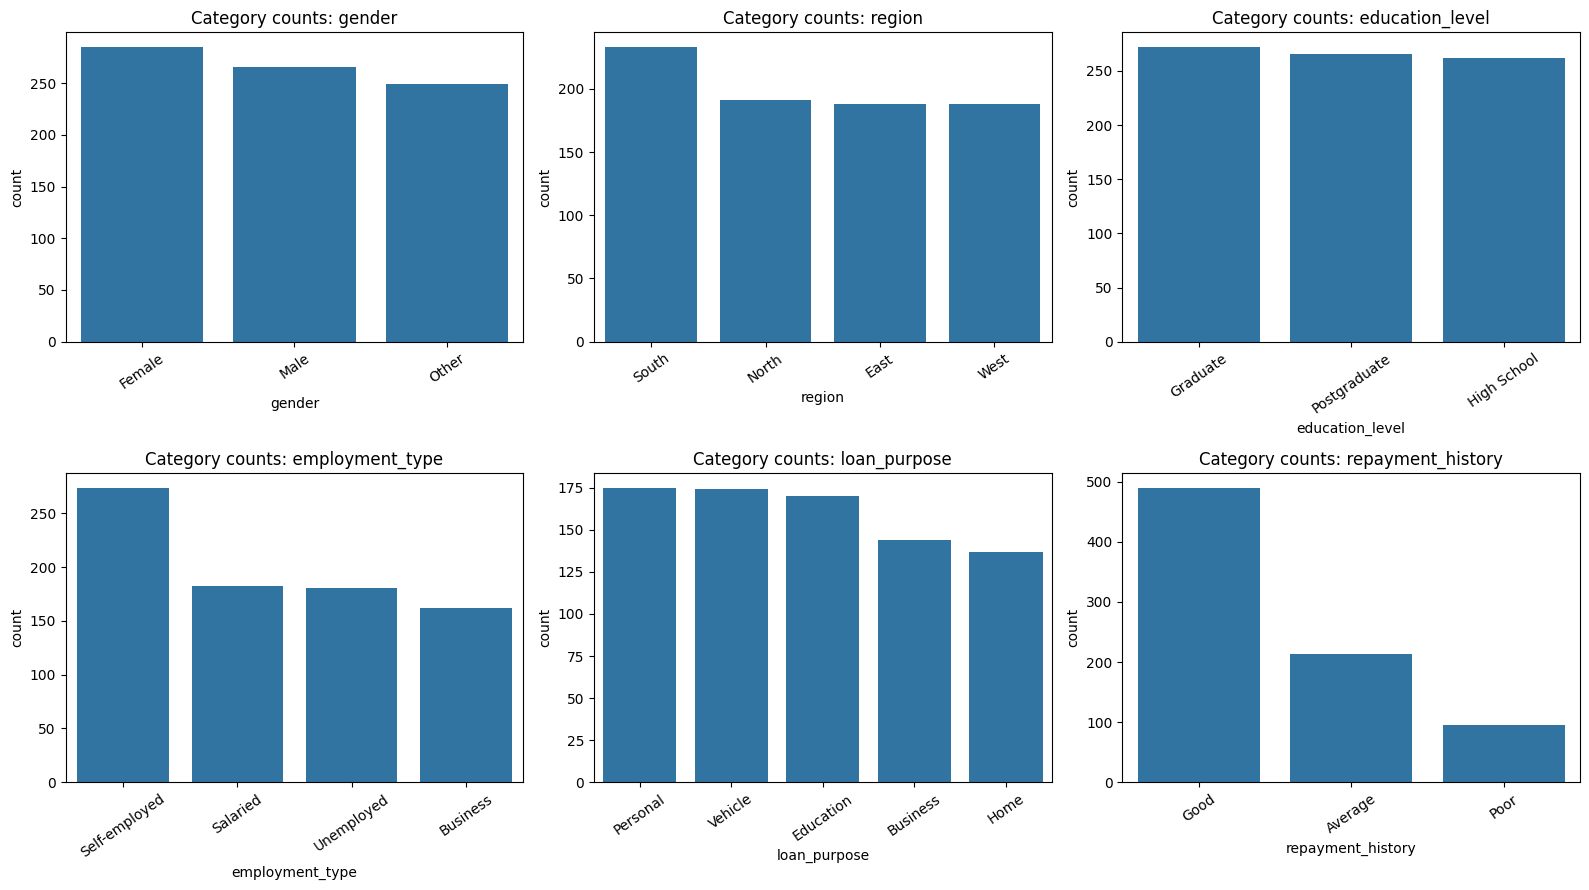

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, categorical_features):
    order = train[col].value_counts().index
    sns.countplot(data=train, x=col, order=order, ax=ax)
    ax.set_title(f"Category counts: {col}")
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()

## 13. Final validation

In [13]:
saved_train = pd.read_csv(PROCESSED_DIR / "customer_credit_risk_day05_train_encoded.csv")
saved_test = pd.read_csv(PROCESSED_DIR / "customer_credit_risk_day05_test_encoded.csv")
saved_all = pd.read_csv(PROCESSED_DIR / "customer_credit_risk_day05_encoded.csv")

validation = pd.DataFrame([
    {"check":"Train and test feature columns match","passed":list(X_train_encoded.columns)==list(X_test_encoded.columns)},
    {"check":"Customer ID excluded from model features","passed":"customer_id" not in X_train_encoded.columns},
    {"check":"Target excluded from model features","passed":"default_flag" not in X_train_encoded.columns},
    {"check":"Target values remain binary","passed":set(saved_all["default_flag"].unique()).issubset({0,1})},
    {"check":"Combined row count preserved","passed":len(saved_all)==len(df)},
    {"check":"Train/test rows add up to full dataset","passed":len(saved_train)+len(saved_test)==len(df)}
])
display(validation)
validation.to_csv(REPORT_DIR / "day05_final_validation_report.csv", index=False)
assert validation["passed"].all(), "One or more Day 5 validation checks failed."

,check,passed
0,Train and test feature columns match,True
1,Customer ID excluded from model features,True
2,Target excluded from model features,True
3,Target values remain binary,True
4,Combined row count preserved,True
5,Train/test rows add up to full dataset,True
